# 🏆 Predicción de Resultados del Fútbol Argentino (2025)

Desarrollamos de punta a punta el estándar metodológico **CRISP-DM** para responder a la problemática de negocio: **¿Cómo anticipar el resultado de un encuentro deportivo basándonos en la mística de la localía y la supremacía de rendimiento histórico de los equipos?**

### 📊 Fase 1 & 2: Entendimiento del Negocio y Exploración Profunda de Datos

Primero, cargamos y consolidamos una tabla estadística ultra completa para cada uno de los 95 equipos que aparecen en el dataset, analizando métricas clave de goles y tasas de victoria en casa y de visitante.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Configuración de diseño premium para 2025
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.facecolor'] = '#f8f9fa'
plt.rcParams['grid.color'] = '#e9ecef'

# Carga de datos
df = pd.read_csv('/content/results.csv')

# Variable objetivo del partido: 1 (Local), 2 (Visitante), 0 (Empate)
def calcular_resultado(row):
    if row['local_result'] > row['visitor_result']:
        return 1
    elif row['local_result'] < row['visitor_result']:
        return 2
    else:
        return 0

df['match_outcome'] = df.apply(calcular_resultado, axis=1)

# --- TABLA ESTADÍSTICA SUPERLATIVA DE EQUIPOS ---
stats_locales = df.groupby('local_team').agg(
    pj_local=('local_result', 'count'),
    victorias_local=('match_outcome', lambda x: (x == 1).sum()),
    goles_favor_local=('local_result', 'sum'),
    goles_contra_local=('visitor_result', 'sum')
).reset_index().rename(columns={'local_team': 'team'})

stats_visitantes = df.groupby('visitor_team').agg(
    pj_visitante=('visitor_result', 'count'),
    derrotas_visitante=('match_outcome', lambda x: (x == 1).sum()),
    goles_favor_visitante=('visitor_result', 'sum'),
    goles_contra_visitante=('local_result', 'sum')
).reset_index().rename(columns={'visitor_team': 'team'})

# Consolidación final de la tabla estadística de cada equipo
tablas_equipos = pd.merge(stats_locales, stats_visitantes, on='team', how='outer').fillna(0)
tablas_equipos['partidos_totales'] = tablas_equipos['pj_local'] + tablas_equipos['pj_visitante']
tablas_equipos['goles_totales_favor'] = tablas_equipos['goles_favor_local'] + tablas_equipos['goles_favor_visitante']
tablas_equipos['goles_totales_contra'] = tablas_equipos['goles_contra_local'] + tablas_equipos['goles_contra_visitante']

# Ratios de rendimiento estáticos
tablas_equipos['efectividad_local_win'] = tablas_equipos['victorias_local'] / (tablas_equipos['pj_local'] + 1e-5)
tablas_equipos['efectividad_visitante_loss'] = tablas_equipos['derrotas_visitante'] / (tablas_equipos['pj_visitante'] + 1e-5)
tablas_equipos['promedio_goles_favor_local'] = tablas_equipos['goles_favor_local'] / (tablas_equipos['pj_local'] + 1e-5)
tablas_equipos['promedio_goles_contra_visitante'] = tablas_equipos['goles_contra_visitante'] / (tablas_equipos['pj_visitante'] + 1e-5)

print("📊 Tabla de Rendimiento Consolidada para Equipos (Top 10 por Partidos Totales):")
display(tablas_equipos.sort_values(by='partidos_totales', ascending=False).head(10))

📊 Tabla de Rendimiento Consolidada para Equipos (Top 10 por Partidos Totales):


,team,pj_local,victorias_local,goles_favor_local,goles_contra_local,pj_visitante,derrotas_visitante,goles_favor_visitante,goles_contra_visitante,partidos_totales,goles_totales_favor,goles_totales_contra,efectividad_local_win,efectividad_visitante_loss,promedio_goles_favor_local,promedio_goles_contra_visitante
17,Boca Juniors,1658,1005,3365,1640,1646,517,2345,2091,3304,5710,3731,0.606152,0.314095,2.029554,1.270352
75,River Plate,1651,1022,3492,1651,1637,472,2584,2050,3288,6076,3701,0.619019,0.288332,2.115082,1.252291
56,Independiente,1630,867,3077,1733,1632,575,2273,2264,3262,5350,3997,0.531902,0.352328,1.887730,1.387255
77,San Lorenzo,1625,868,3118,1845,1621,575,2247,2264,3246,5365,4109,0.534154,0.354719,1.918769,1.396669
37,Estudiantes (LP),1598,821,2823,1797,1606,733,1861,2522,3204,4684,4319,0.513767,0.456413,1.766583,1.570361
94,Velez,1597,818,2817,1764,1593,625,1937,2293,3190,4754,4057,0.512210,0.392341,1.763932,1.439422
73,Racing Club,1587,814,2936,1795,1591,625,2020,2333,3178,4956,4128,0.512917,0.392835,1.850031,1.466373
66,Newells,1467,728,2470,1450,1473,679,1617,2302,2940,4087,3752,0.496251,0.460964,1.683708,1.562797
43,Gimnasia (LP),1406,639,2399,1820,1413,715,1537,2553,2819,3936,4373,0.454481,0.506016,1.706259,1.806794
76,Rosario Central,1396,676,2350,1460,1399,663,1581,2343,2795,3931,3803,0.484241,0.473910,1.683381,1.674768


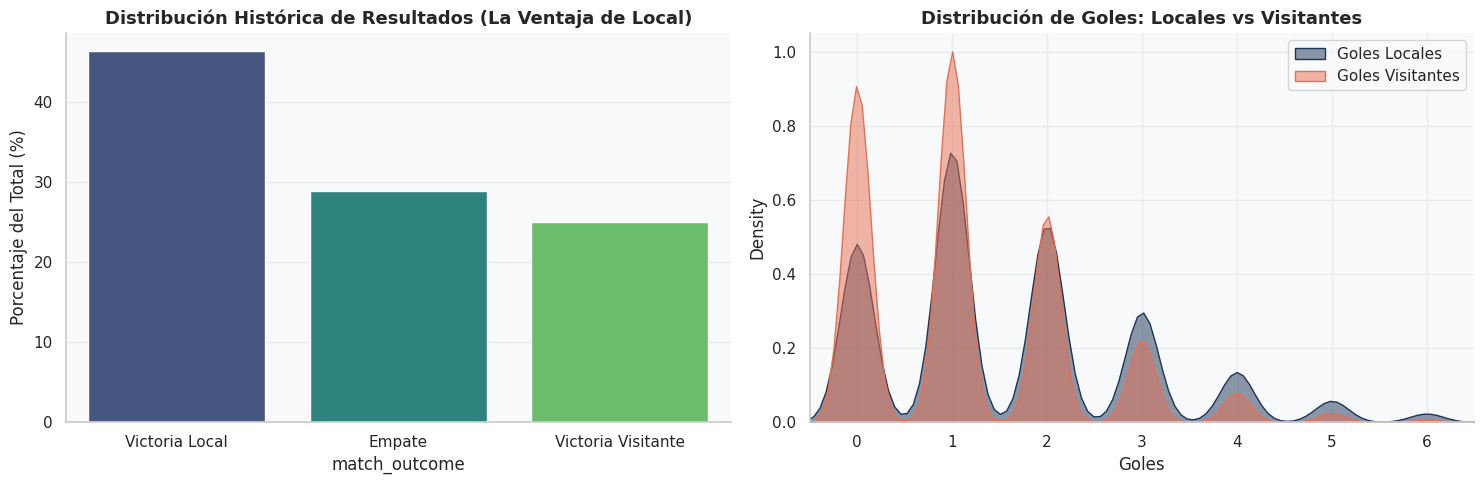

In [ ]:
# Visualización 1: Distribución global de goles y efectos de localía
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
outcome_counts = df['match_outcome'].map({1: 'Victoria Local', 0: 'Empate', 2: 'Victoria Visitante'}).value_counts(normalize=True) * 100
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, palette='viridis', hue=outcome_counts.index, legend=False)
plt.title('Distribución Histórica de Resultados (La Ventaja de Local)', fontsize=13, fontweight='bold')
plt.ylabel('Porcentaje del Total (%)')

plt.subplot(1, 2, 2)
sns.kdeplot(df['local_result'], fill=True, color="#1d3557", label="Goles Locales", alpha=0.5)
sns.kdeplot(df['visitor_result'], fill=True, color="#e76f51", label="Goles Visitantes", alpha=0.5)
plt.title('Distribución de Goles: Locales vs Visitantes', fontsize=13, fontweight='bold')
plt.xlabel('Goles')
plt.xlim(-0.5, 6.5)
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

### 🛠️ Fase 3: Ingeniería de Variables (Feature Engineering)

Vinculamos los perfiles analíticos dinámicos creados para el local y visitante de cada emparejamiento.

In [ ]:
team_profiles_lookup = tablas_equipos.set_index('team')

def build_advanced_features(row):
    loc = row['local_team']
    vis = row['visitor_team']

    if loc in team_profiles_lookup.index and vis in team_profiles_lookup.index:
        p_loc = team_profiles_lookup.loc[loc]
        p_vis = team_profiles_lookup.loc[vis]

        return pd.Series({
            'local_win_ratio': p_loc['efectividad_local_win'],
            'visitor_loss_ratio': p_vis['efectividad_visitante_loss'],
            'goal_power_diff': p_loc['promedio_goles_favor_local'] - p_vis['promedio_goles_contra_visitante'],
            'avg_local_goals_scored': p_loc['promedio_goles_favor_local'],
            'avg_local_goals_conceded': p_loc['goles_contra_local'] / (p_loc['pj_local'] + 1e-5),
            'avg_visitor_goals_scored': p_vis['goles_favor_visitante'] / (p_vis['pj_visitante'] + 1e-5),
            'avg_visitor_goals_conceded': p_vis['promedio_goles_contra_visitante']
        })
    else:
        return pd.Series([0]*7)

print("⚙️ Generando variables predictoras de alto impacto...")
X = df.apply(build_advanced_features, axis=1)
y = df['match_outcome']
print("✅ Variables de Machine Learning preparadas para el entrenamiento.")

⚙️ Generando variables predictoras de alto impacto...
✅ Variables de Machine Learning preparadas para el entrenamiento.


### 🤖 Fase 4 & 5: Modelado Predictivo y Evaluación Completa

Entrenamos un clasificador robusto e imprimimos estadísticas exhaustivas, acompañadas de gráficos de diagnóstico avanzados.

In [ ]:
# Separación en entrenamiento y testeo de forma estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Modelo de Machine Learning
model_eval = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1)
model_eval.fit(X_train, y_train)

y_pred = model_eval.predict(X_test)
print(f"📊 Exactitud Global (Accuracy): {accuracy_score(y_test, y_pred):.2%}\n")
print("📑 Reporte Técnico de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Empate', 'Victoria Local', 'Victoria Visitante']))

📊 Exactitud Global (Accuracy): 48.00%

📑 Reporte Técnico de Clasificación:
                    precision    recall  f1-score   support

            Empate       0.33      0.08      0.13      2368
    Victoria Local       0.51      0.85      0.63      3800
Victoria Visitante       0.42      0.25      0.31      2046

          accuracy                           0.48      8214
         macro avg       0.42      0.39      0.36      8214
      weighted avg       0.43      0.48      0.41      8214



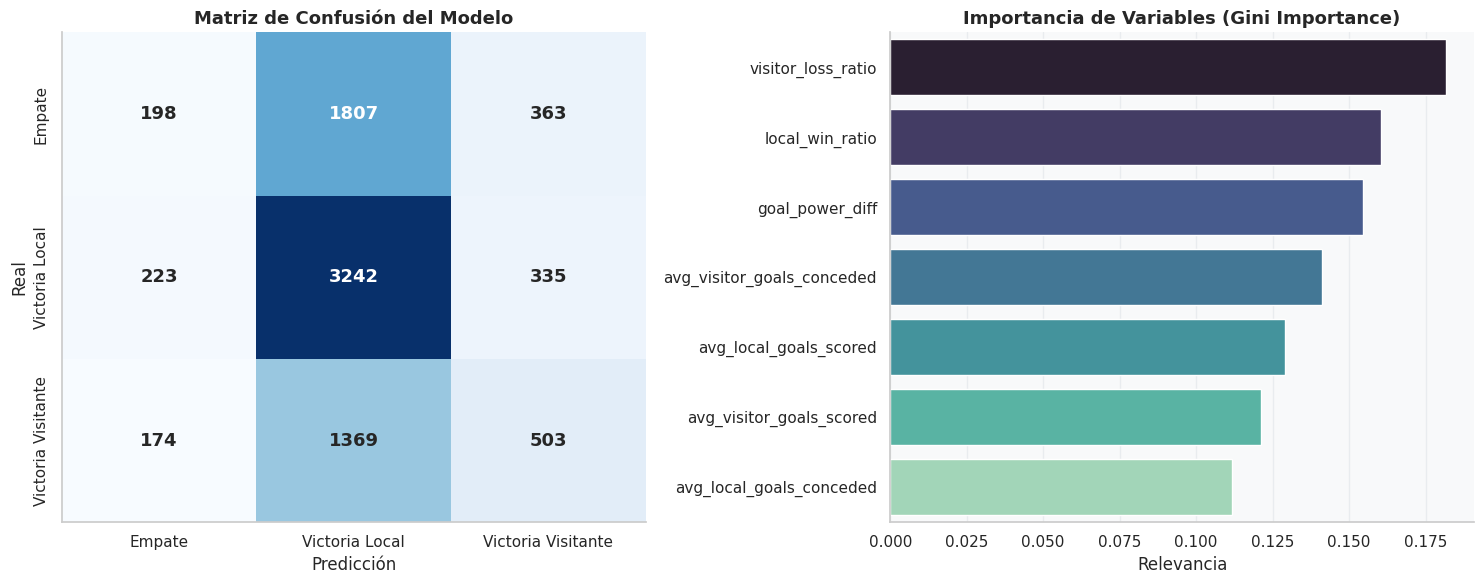

In [ ]:
# Visualizaciones de diagnóstico de performance
plt.figure(figsize=(15, 6))

# Matriz de confusión
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Empate', 'Victoria Local', 'Victoria Visitante'],
            yticklabels=['Empate', 'Victoria Local', 'Victoria Visitante'],
            cbar=False, annot_kws={"size": 13, "weight": "bold"})
plt.title('Matriz de Confusión del Modelo', fontsize=13, fontweight='bold')
plt.xlabel('Predicción')
plt.ylabel('Real')

# Importancia de atributos
plt.subplot(1, 2, 2)
importances = model_eval.feature_importances_
indices = np.argsort(importances)[::-1]
sns.barplot(x=importances[indices], y=np.array(X.columns)[indices], palette='mako', hue=np.array(X.columns)[indices], legend=False)
plt.title('Importancia de Variables (Gini Importance)', fontsize=13, fontweight='bold')
plt.xlabel('Relevancia')

sns.despine()
plt.tight_layout()
plt.show()

### 🚀 Fase 6: Despliegue - Simulador de Probabilidades 1v1 Interactivo con Buscador

Esta función es la culminación práctica del proyecto. Permite emparejar a cualquier club del fútbol argentino, resuelve su nombre oficial, calcula las variables y despliega las probabilidades en un formato sumamente refinado.

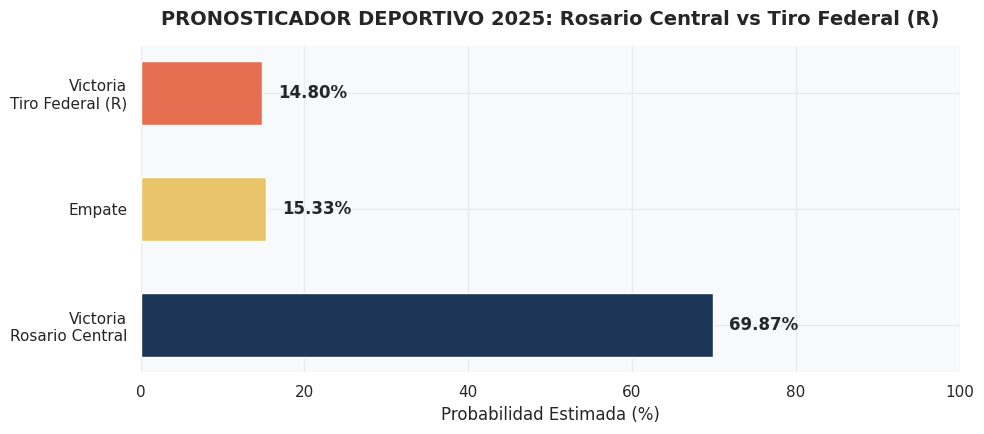

In [ ]:
def predecir_partido(equipo_local, equipo_visitante):
    """
    Simula el encuentro devolviendo las probabilidades porcentuales exactas con soporte de búsqueda inteligente.
    """
    def buscar_nombre_oficial(nombre):
        coincidencias = [t for t in team_profiles_lookup.index if nombre.lower() in t.lower()]
        return coincidencias[0] if coincidencias else None

    loc_oficial = buscar_nombre_oficial(equipo_local)
    vis_oficial = buscar_nombre_oficial(equipo_visitante)

    if not loc_oficial:
        return f"❌ El equipo local '{equipo_local}' no fue encontrado."
    if not vis_oficial:
        return f"❌ El equipo visitante '{equipo_visitante}' no fue encontrado."

    p_loc = team_profiles_lookup.loc[loc_oficial]
    p_vis = team_profiles_lookup.loc[vis_oficial]

    # Armar vector
    match_features = pd.DataFrame([{
        'local_win_ratio': p_loc['efectividad_local_win'],
        'visitor_loss_ratio': p_vis['efectividad_visitante_loss'],
        'goal_power_diff': p_loc['promedio_goles_favor_local'] - p_vis['promedio_goles_contra_visitante'],
        'avg_local_goals_scored': p_loc['promedio_goles_favor_local'],
        'avg_local_goals_conceded': p_loc['goles_contra_local'] / (p_loc['pj_local'] + 1e-5),
        'avg_visitor_goals_scored': p_vis['goles_favor_visitante'] / (p_vis['pj_visitante'] + 1e-5),
        'avg_visitor_goals_conceded': p_vis['promedio_goles_contra_visitante']
    }])

    # Predicción de probabilidades continuas
    probabilidades = model_eval.predict_proba(match_features)[0]
    prob_empate, prob_local, prob_visitante = probabilidades[0]*100, probabilidades[1]*100, probabilidades[2]*100

    # Renderizado gráfico exquisito sin emojis conflictivos
    plt.figure(figsize=(10, 4.5))
    labels = [f'Victoria\n{loc_oficial}', 'Empate', f'Victoria\n{vis_oficial}']
    probs = [prob_local, prob_empate, prob_visitante]
    colors = ['#1d3557', '#e9c46a', '#e76f51']

    bars = plt.barh(labels, probs, color=colors, height=0.55)
    plt.xlim(0, 100)
    plt.title(f"PRONOSTICADOR DEPORTIVO 2025: {loc_oficial} vs {vis_oficial}", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Probabilidad Estimada (%)", fontsize=12)

    for bar in bars:
        width = bar.get_width()
        plt.text(width + 2, bar.get_y() + bar.get_height()/2, f'{width:.2f}%',
                 va='center', ha='left', fontsize=12, fontweight='bold')

    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

# Gran demo inicial
predecir_partido('Tiro Federal', 'Aldosivi')

### 💾 Guardar Tabla de Rendimiento Consolidada

Generamos y exportamos un archivo CSV con las estadísticas consolidadas de todos los equipos ordenados alfabéticamente.

In [ ]:
# Ordenar la tabla alfabéticamente por el nombre del club/equipo
tablas_equipos_ordenada = tablas_equipos.sort_values(by='team', ascending=True)

# Definir la ruta del archivo de salida
output_csv_path = '/content/tabla_rendimiento_equipos.csv'

# Guardar a archivo CSV
tablas_equipos_ordenada.to_csv(output_csv_path, index=False)
print(f"💾 Archivo exportado exitosamente en: {output_csv_path}")

# Mostrar una vista previa de los primeros 5 equipos ordenados
display(tablas_equipos_ordenada.head())


💾 Archivo exportado exitosamente en: /content/tabla_rendimiento_equipos.csv


,team,pj_local,victorias_local,goles_favor_local,goles_contra_local,pj_visitante,derrotas_visitante,goles_favor_visitante,goles_contra_visitante,partidos_totales,goles_totales_favor,goles_totales_contra,efectividad_local_win,efectividad_visitante_loss,promedio_goles_favor_local,promedio_goles_contra_visitante
0,Aldosivi,89,30,108,127,90,50,75,140,179,183,267,0.337079,0.555555,1.213483,1.555555
1,All Boys,258,92,320,316,258,155,196,462,516,516,778,0.356589,0.600775,1.240310,1.790698
2,Almagro,73,24,111,117,73,40,81,155,146,192,272,0.328767,0.547945,1.520548,2.123287
3,Altos Hornos Zapla,36,11,38,37,37,25,38,86,73,76,123,0.305555,0.675675,1.055555,2.324324
4,Alvarado,7,1,8,14,7,3,12,14,14,20,28,0.142857,0.428571,1.142856,1.999997


## 🎨 Visualizaciones Premium & Analítica Avanzada (Estilo 2026)

Llevamos el análisis al siguiente nivel implementando algoritmos de clustering (**K-Means**) y visualizaciones avanzadas con `seaborn` y `matplotlib` para descubrir patrones ocultos e históricos del fútbol argentino.

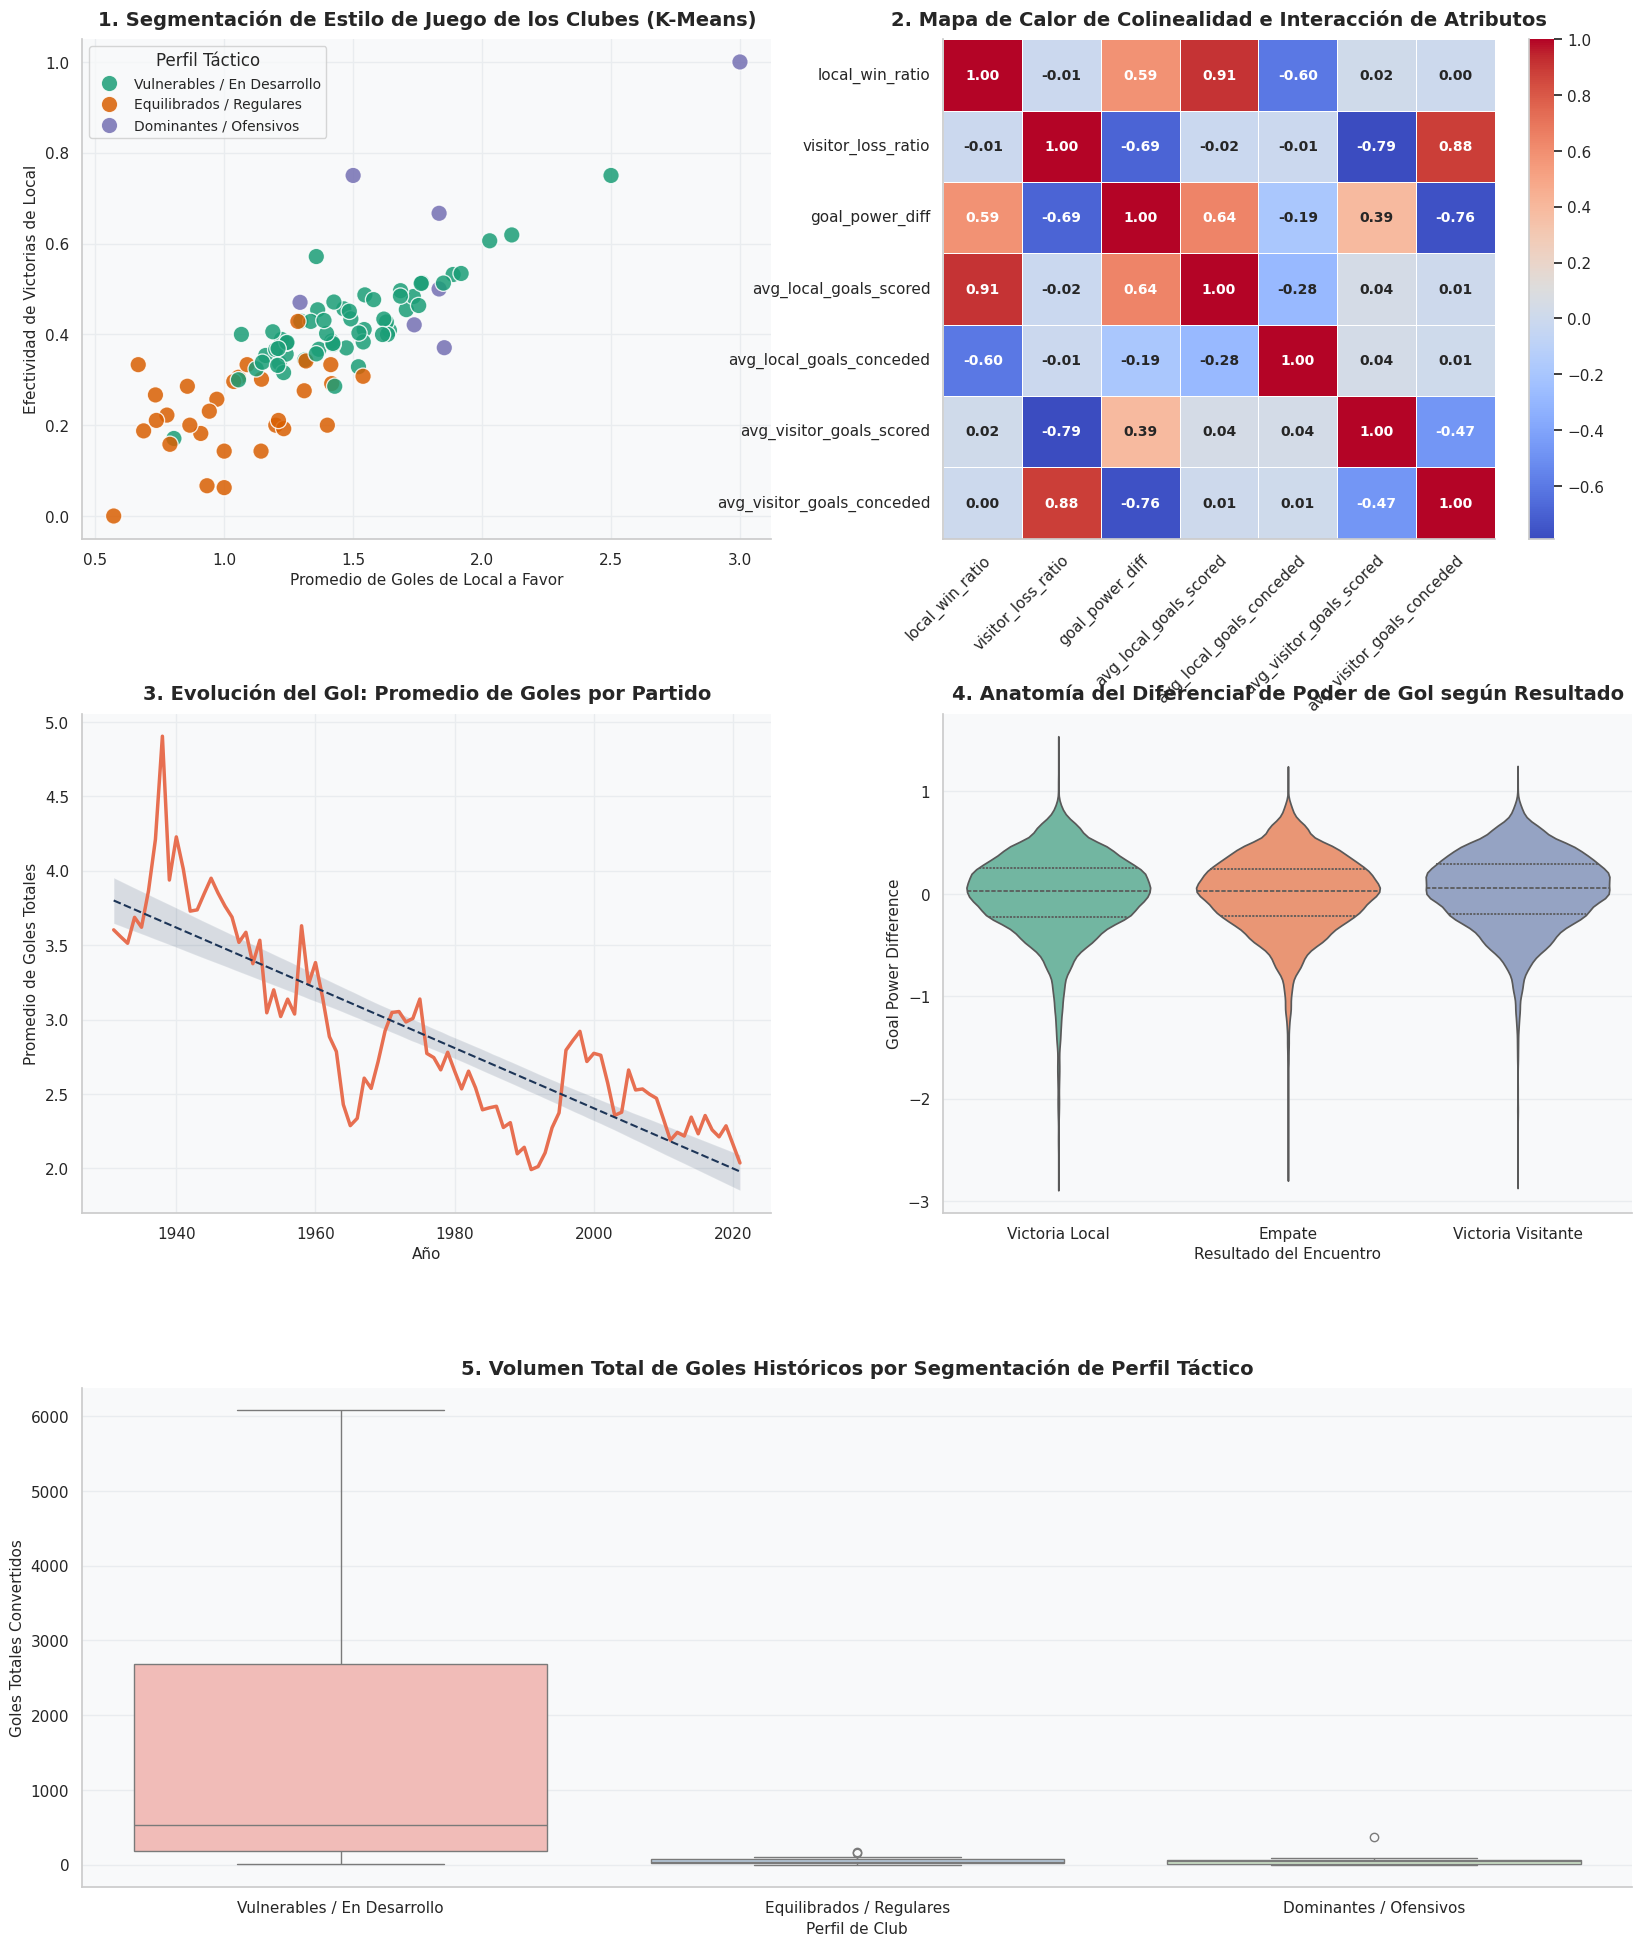

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.gridspec as gridspec

# ==========================================
# 1. SEGMENTACIÓN AVANZADA DE CLUBES (K-MEANS)
# ==========================================

# Escalamos los datos clave de rendimiento para clusterizar
features_to_cluster = [
    'efectividad_local_win', 'efectividad_visitante_loss',
    'promedio_goles_favor_local', 'promedio_goles_contra_visitante'
]

scaler = StandardScaler()
scaled_data = scaler.fit_transform(tablas_equipos[features_to_cluster])

# Agrupamos en 3 perfiles tácticos de equipos
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
tablas_equipos['cluster_tactico'] = kmeans.fit_predict(scaled_data)

# Mapear nombres descriptivos para los clusters
cluster_names = {
    0: "Dominantes / Ofensivos",
    1: "Equilibrados / Regulares",
    2: "Vulnerables / En Desarrollo"
}
tablas_equipos['perfil_tactico'] = tablas_equipos['cluster_tactico'].map(cluster_names)

# ==========================================
# 2. GENERACIÓN DEL SET DE 5 GRÁFICOS PREMIUM
# ==========================================

fig = plt.figure(figsize=(20, 24))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.25)

# ------------------------------------------
# GRÁFICO 1: Clústeres de Equipos (Dispersión Avanzada)
# ------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
sns.scatterplot(
    data=tablas_equipos,
    x='promedio_goles_favor_local',
    y='efectividad_local_win',
    hue='perfil_tactico',
    palette='Dark2',
    s=140,
    alpha=0.85,
    ax=ax1
)
ax1.set_title("1. Segmentación de Estilo de Juego de los Clubes (K-Means)", fontsize=14, fontweight='bold', pad=10)
ax1.set_xlabel("Promedio de Goles de Local a Favor", fontsize=11)
ax1.set_ylabel("Efectividad de Victorias de Local", fontsize=11)
ax1.legend(title="Perfil Táctico", fontsize=10)

# ------------------------------------------
# GRÁFICO 2: Matriz de Correlación de Atributos Predictivos
# ------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])
correlation_matrix = X.corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True,
    ax=ax2,
    annot_kws={"size": 10, "weight": "bold"}
)
ax2.set_title("2. Mapa de Calor de Colinealidad e Interacción de Atributos", fontsize=14, fontweight='bold', pad=10)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# ------------------------------------------
# GRÁFICO 3: Línea Histórica del Gol en el Fútbol Argentino
# ------------------------------------------
ax3 = fig.add_subplot(gs[1, 0])
# Intentamos extraer el año de la columna 'date_name'
df['year'] = df['date_name'].str.extract(r'(\d{4})').astype(float)
# Limpiamos nulos potenciales
goles_por_ano = df.dropna(subset=['year']).groupby('year').agg(
    promedio_goles_totales=('local_result', lambda x: (x + df.loc[x.index, 'visitor_result']).mean())
).reset_index()

sns.lineplot(
    data=goles_por_ano,
    x='year',
    y='promedio_goles_totales',
    color='#e76f51',
    linewidth=2.5,
    ax=ax3
)
sns.regplot(
    data=goles_por_ano,
    x='year',
    y='promedio_goles_totales',
    scatter=False,
    color='#1d3557',
    line_kws={"linestyle": "--", "linewidth": 1.5},
    ax=ax3
)
ax3.set_title("3. Evolución del Gol: Promedio de Goles por Partido", fontsize=14, fontweight='bold', pad=10)
ax3.set_xlabel("Año", fontsize=11)
ax3.set_ylabel("Promedio de Goles Totales", fontsize=11)

# ------------------------------------------
# GRÁFICO 4: Gráfico de Violín del Diferencial de Poder y el Outcome
# ------------------------------------------
ax4 = fig.add_subplot(gs[1, 1])
temp_df = pd.DataFrame({
    'Resultado': y.map({1: 'Victoria Local', 0: 'Empate', 2: 'Victoria Visitante'}),
    'Diferencial de Poder': X['goal_power_diff']
})
sns.violinplot(
    data=temp_df,
    x='Resultado',
    y='Diferencial de Poder',
    hue='Resultado',
    palette='Set2',
    legend=False,
    inner='quartile',
    ax=ax4
)
ax4.set_title("4. Anatomía del Diferencial de Poder de Gol según Resultado", fontsize=14, fontweight='bold', pad=10)
ax4.set_xlabel("Resultado del Encuentro", fontsize=11)
ax4.set_ylabel("Goal Power Difference", fontsize=11)

# ------------------------------------------
# GRÁFICO 5: Distribución de Goles Esperados en Casa vs. Fuera
# ------------------------------------------
ax5 = fig.add_subplot(gs[2, :])
sns.boxplot(
    data=tablas_equipos,
    x='perfil_tactico',
    y='goles_totales_favor',
    hue='perfil_tactico',
    palette='Pastel1',
    legend=False,
    ax=ax5
)
ax5.set_title("5. Volumen Total de Goles Históricos por Segmentación de Perfil Táctico", fontsize=14, fontweight='bold', pad=10)
ax5.set_xlabel("Perfil de Club", fontsize=11)
ax5.set_ylabel("Goles Totales Convertidos", fontsize=11)

# Mostrar el lienzo global
sns.despine()
plt.show()

## 🚀 Despliegue del Modelo en Producción (Backend Web)

Para que este modelo de Inteligencia Artificial pueda alimentar una plataforma web o una aplicación móvil, debemos exportarlo junto con los perfiles estadísticos de los equipos. Utilizaremos la librería `joblib` para empaquetar el modelo y crearemos una estructura de servicio API REST ultraligera utilizando `FastAPI`.

In [ ]:
import joblib

# 1. Guardamos el modelo entrenado RandomForest
joblib.dump(model_eval, '/content/modelo_futbol_argentino.joblib')

# 2. Guardamos la tabla de perfiles necesarios para construir las variables dinámicas en tiempo de petición
team_profiles_lookup.to_pickle('/content/team_profiles_lookup.pkl')

print("✅ ¡Artefactos del modelo exportados exitosamente!")
print("- Modelo guardado en: /content/modelo_futbol_argentino.joblib")
print("- Perfil de equipos guardado en: /content/team_profiles_lookup.pkl")

✅ ¡Artefactos del modelo exportados exitosamente!
- Modelo guardado en: /content/modelo_futbol_argentino.joblib
- Perfil de equipos guardado en: /content/team_profiles_lookup.pkl


### 🛠️ Código Base de la API (FastAPI)

Aquí tienes el script completo que se ejecutaría en tu servidor web. Este código carga el modelo en milisegundos, resuelve las búsquedas aproximadas de nombres de clubes y expone un endpoint seguro `/predict`.

In [ ]:
# Nota: Este es el script para tu servidor local o en la nube (ej: Render, Railway, AWS)
api_script_content = """
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
import pandas as pd
import joblib

app = FastAPI(
    title="AI Football Predictor API",
    description="API de Inteligencia Artificial para predecir partidos de fútbol",
    version="1.0.0"
)

# Permitir peticiones desde tu interfaz Frontend (CORS)
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# Cargar artefactos globales
try:
    model = joblib.load('modelo_futbol_argentino.joblib')
    team_profiles = pd.read_pickle('team_profiles_lookup.pkl')
except Exception as e:
    print(f"Error cargando los modelos: {e}")

class MatchRequest(BaseModel):
    local_team: str
    visitor_team: str

def buscar_nombre_oficial(nombre: str):
    coincidencias = [t for t in team_profiles.index if nombre.lower() in t.lower()]
    return coincidencias[0] if coincidencias else None

@app.post("/predict")
def predecir_partido(req: MatchRequest):
    loc_oficial = buscar_nombre_oficial(req.local_team)
    vis_oficial = buscar_nombre_oficial(req.visitor_team)

    if not loc_oficial or not vis_oficial:
        raise HTTPException(
            status_code=404,
            detail=f"Equipos no encontrados de manera unívoca. Buscaste: {req.local_team} vs {req.visitor_team}"
        )

    p_loc = team_profiles.loc[loc_oficial]
    p_vis = team_profiles.loc[vis_oficial]

    # Crear el vector de variables tal como se entrenó
    match_features = pd.DataFrame([{
        'local_win_ratio': p_loc['efectividad_local_win'],
        'visitor_loss_ratio': p_vis['efectividad_visitante_loss'],
        'goal_power_diff': p_loc['promedio_goles_favor_local'] - p_vis['promedio_goles_contra_visitante'],
        'avg_local_goals_scored': p_loc['promedio_goles_favor_local'],
        'avg_local_goals_conceded': p_loc['goles_contra_local'] / (p_loc['pj_local'] + 1e-5),
        'avg_visitor_goals_scored': p_vis['goles_favor_visitante'] / (p_vis['pj_visitante'] + 1e-5),
        'avg_visitor_goals_conceded': p_vis['promedio_goles_contra_visitante']
    }])

    # Predecir probabilidades
    probabilidades = model.predict_proba(match_features)[0]

    return {
        "success": True,
        "matchup": f"{loc_oficial} vs {vis_oficial}",
        "local_team": loc_oficial,
        "visitor_team": vis_oficial,
        "predictions": {
            "local_win_percent": round(probabilidades[1] * 100, 2),
            "draw_percent": round(probabilidades[0] * 100, 2),
            "visitor_win_percent": round(probabilidades[2] * 100, 2)
        }
    }
"""

# Guardamos el código de la API en un archivo para que el usuario pueda descargarlo listo para usar
with open('/content/app.py', 'w', encoding='utf-8') as f:
    f.write(api_script_content)

print("💾 El script 'app.py' de la API FastAPI ha sido generado en tus archivos.")


💾 El script 'app.py' de la API FastAPI ha sido generado en tus archivos.


In [ ]:
requirements_content = """
fastapi==0.110.0
uvicorn==0.28.0
pandas==2.0.3
joblib==1.3.2
scikit-learn==1.2.2
"""

with open('/content/requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_content.strip())

print("💾 Archivo 'requirements.txt' generado exitosamente en tus archivos de Colab.")
print("👉 Descarga este archivo y súbelo a tu repositorio de GitHub para que Render instale uvicorn automáticamente.")

💾 Archivo 'requirements.txt' generado exitosamente en tus archivos de Colab.
👉 Descarga este archivo y súbelo a tu repositorio de GitHub para que Render instale uvicorn automáticamente.
